<style>
h1, h2, h3, h4, h5, h6, th, strong, b,
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2,
.jp-RenderedHTMLCommon h3, .jp-RenderedHTMLCommon th {
  font-weight: 400 !important;
}
</style>

# Modern Optics Lab 3
## 3D PSF, OTF, and Pupil Engineering

Fluorescent microspheres were used to measure the 3D PSF and OTF. Results from an open pupil (1), horizontal slit (3), and central obstruction (4) were compared with scalar diffraction simulations.

### 1. Optical setup and acquisition

The detection path includes an objective, emission filter, 100 mm lens, and Thorlabs DCC3240C camera. At 5× magnification, 5.3 µm camera pixels correspond to 1.06 µm at the sample. Axial scanning used nominal 1 µm steps, with three exposures per position.

The simulation used a 25 mm open pupil (1), a 20 × 0.5 mm slit (3), and an obstructed pupil with a 2 mm central stop (4), at an assumed wavelength of 532 nm. Some aperture dimensions were estimated from the drawing.

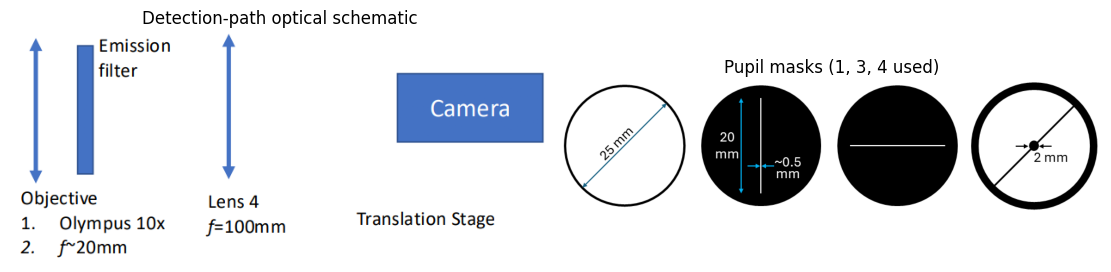

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tifffile
from scipy.ndimage import gaussian_filter
from scipy.signal.windows import tukey
from IPython.display import display, Image

# Place this notebook in the Lab 3 folder, alongside Data/ and *.npz.
root = Path.cwd()
dxy_um, dz_um = 5.3 / 5, 1.0
folders = {
    1: ('Open pupil', 'cropped_no aperture'),
    3: ('Horizontal slit', 'cropped_center horizontal aperture'),
    4: ('Central obstruction', 'cropped_center block aperture 2'),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
for ax, filename, label in zip(axes,
    ['figures/optical_layout.png', 'figures/aperture_diagram.png'],
    ['Detection-path optical schematic', 'Pupil masks (1, 3, 4 used)']):
    ax.imshow(plt.imread(root / filename))
    ax.set_title(label, fontsize=12)
    ax.axis('off')
plt.show()

Figure 1. Detection-path schematic and pupil masks.

### 2. Experimental 3D PSF and OTF

Each fluorescent bead approximates a point emitter. The 3D OTF is the normalized 3D Fourier transform of the measured PSF:

$$
H(f_x,f_y,f_z)=\frac{\mathcal{F}_{3D}\{h(x,y,z)\}}{\mathcal{F}_{3D}\{h(x,y,z)\}(0,0,0)}.
$$

The following images show raw TIFF frames near focus. Three cropped stacks were available per aperture; missing frame indices make the axial reconstruction approximate.

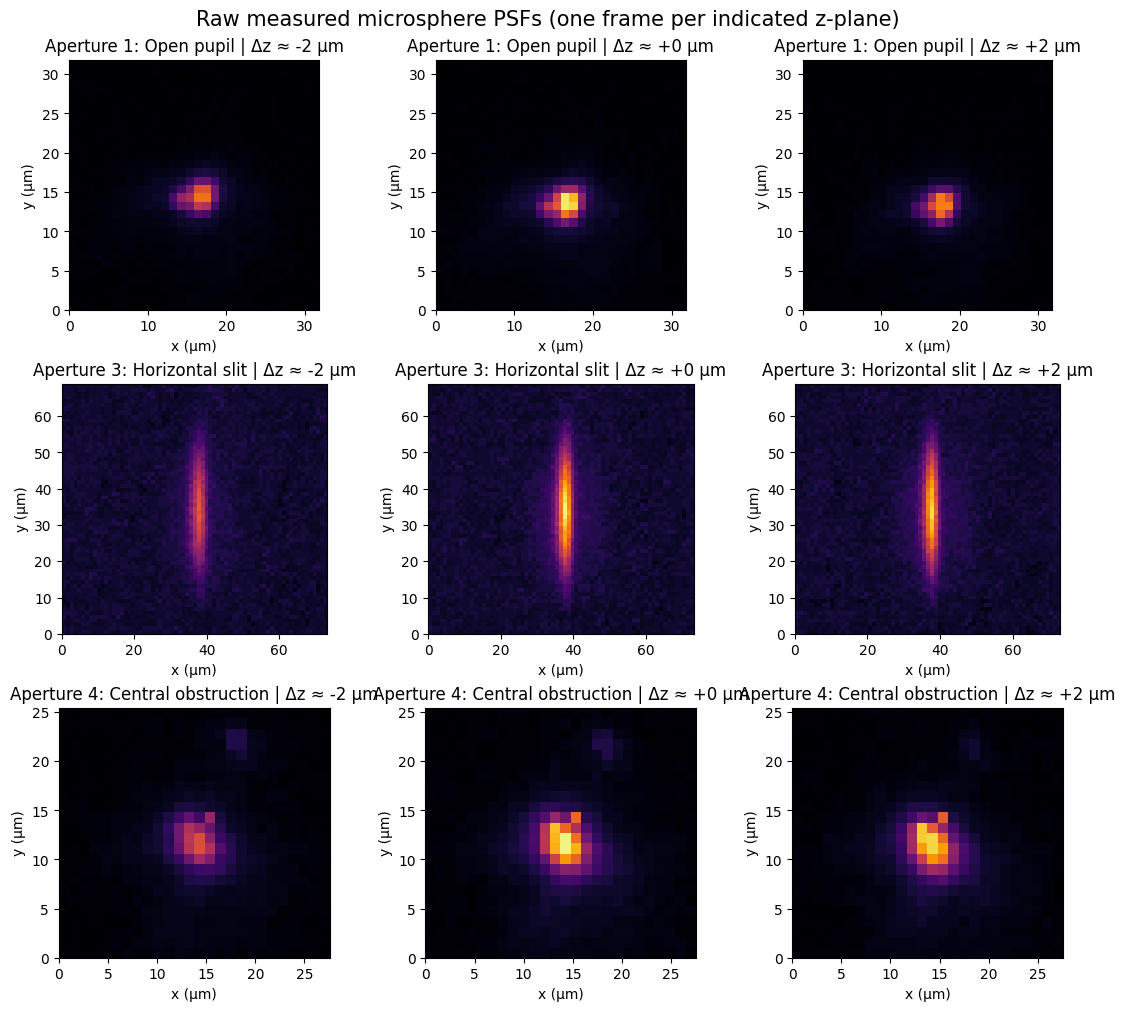

In [2]:
raw_stacks, grouped_psf, otf3d = {}, {}, {}
fig, ax = plt.subplots(3, 3, figsize=(11, 10), layout='constrained')
for r, (ap, (label, folder)) in enumerate(folders.items()):
    raw = tifffile.imread(root / 'Data' / folder / 'cropped_1.tif').astype(float)
    raw_stacks[ap] = raw
    n = len(raw) // 3
    stack = raw[:3*n].reshape(n, 3, *raw.shape[1:]).mean(axis=1)
    bg = np.percentile(stack, 5, axis=(1,2))
    stack = np.maximum(stack - bg[:, None, None], 0)
    grouped_psf[ap] = stack
    smoothed = gaussian_filter(stack, (0, .8, .8))
    focus = int(np.argmax(smoothed.max(axis=(1,2))))
    for c, dz in enumerate((-2, 0, 2)):
        iz = int(np.clip(focus + dz, 0, n - 1))
        raw_img = raw[3*iz]  # one original camera exposure per plane
        ax[r,c].imshow(raw_img, origin='lower', cmap='inferno',
            extent=[0,raw.shape[2]*dxy_um, 0,raw.shape[1]*dxy_um],
            vmin=0, vmax=np.max(raw))
        ax[r,c].set_title(f'Aperture {ap}: {label} | Δz ≈ {iz-focus:+d} µm')
        ax[r,c].set_xlabel('x (µm)')
        ax[r,c].set_ylabel('y (µm)')
plt.suptitle('Raw measured microsphere PSFs (one frame per indicated z-plane)', fontsize=15)
plt.show()

Figure 2. Raw microsphere images at three approximate axial positions for each aperture.

For the 3D OTF, consecutive groups of three frames were averaged and background-subtracted. A boundary window reduced FFT artifacts. The plots show central slices of normalized 3D OTF magnitude.

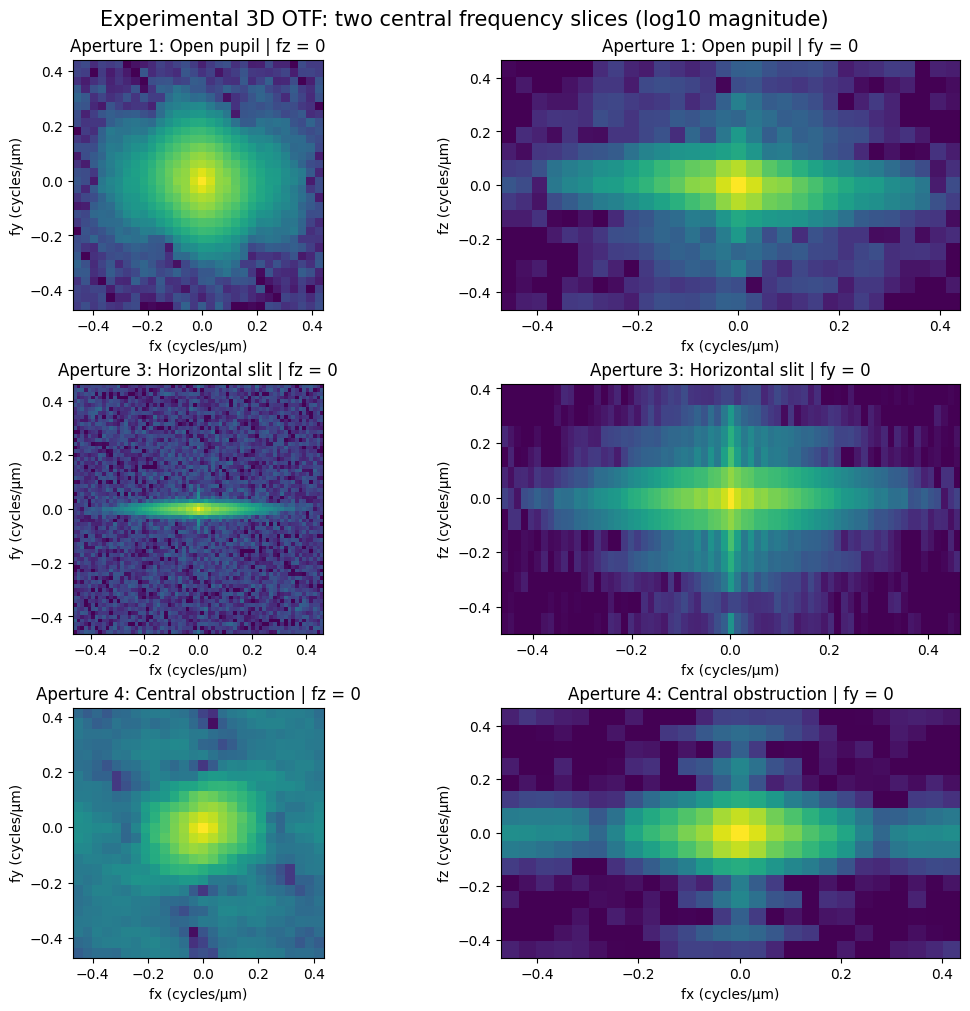

In [3]:
fig, ax = plt.subplots(3, 2, figsize=(10, 10), layout='constrained')
for r, (ap, (label, _)) in enumerate(folders.items()):
    vol = grouped_psf[ap]
    nz, ny, nx = vol.shape
    window = (tukey(nz, .25)[:,None,None] *
              tukey(ny, .25)[None,:,None] *
              tukey(nx, .25)[None,None,:])
    H = np.abs(np.fft.fftshift(np.fft.fftn(vol * window)))
    H /= max(H[nz//2, ny//2, nx//2], 1e-12)
    otf3d[ap] = H
    fx = np.fft.fftshift(np.fft.fftfreq(nx, dxy_um))
    fy = np.fft.fftshift(np.fft.fftfreq(ny, dxy_um))
    fz = np.fft.fftshift(np.fft.fftfreq(nz, dz_um))
    ax[r,0].imshow(np.log10(np.maximum(H[nz//2], 1e-3)), origin='lower',
        extent=[fx[0],fx[-1],fy[0],fy[-1]],cmap='viridis',vmin=-3,vmax=0)
    ax[r,1].imshow(np.log10(np.maximum(H[:,ny//2], 1e-3)), origin='lower',
        extent=[fx[0],fx[-1],fz[0],fz[-1]],cmap='viridis',vmin=-3,vmax=0,aspect='auto')
    ax[r,0].set_title(f'Aperture {ap}: {label} | fz = 0')
    ax[r,1].set_title(f'Aperture {ap}: {label} | fy = 0')
    ax[r,0].set(xlabel='fx (cycles/µm)',ylabel='fy (cycles/µm)')
    ax[r,1].set(xlabel='fx (cycles/µm)',ylabel='fz (cycles/µm)')
plt.suptitle('Experimental 3D OTF: two central frequency slices (log10 magnitude)',fontsize=15)
plt.show()

Figure 3. Experimental 3D OTF magnitude, shown in the lateral and axial frequency planes. The slit reduces the vertical frequency bandwidth. Cropping and uncertain frame positions affect the estimates.

### 3. Numerical ATF, PSF, and OTF

The ATF follows the pupil transmission $P$. The intensity PSF and in-focus OTF are

$$
\mathrm{ATF}\propto P,\qquad
h(x,y;0)\propto|\mathcal{F}^{-1}\{P\}|^2,\qquad
\mathrm{OTF}_{2D}=\frac{\mathcal{F}_{2D}\{h(x,y;0)\}}{\mathcal{F}_{2D}\{h(x,y;0)\}(0,0)}.
$$

The simulated PSFs include pixel integration and pupil defocus. The simulated OTF is an in-focus 2D OTF, whereas Figure 3 shows slices of a measured 3D OTF.

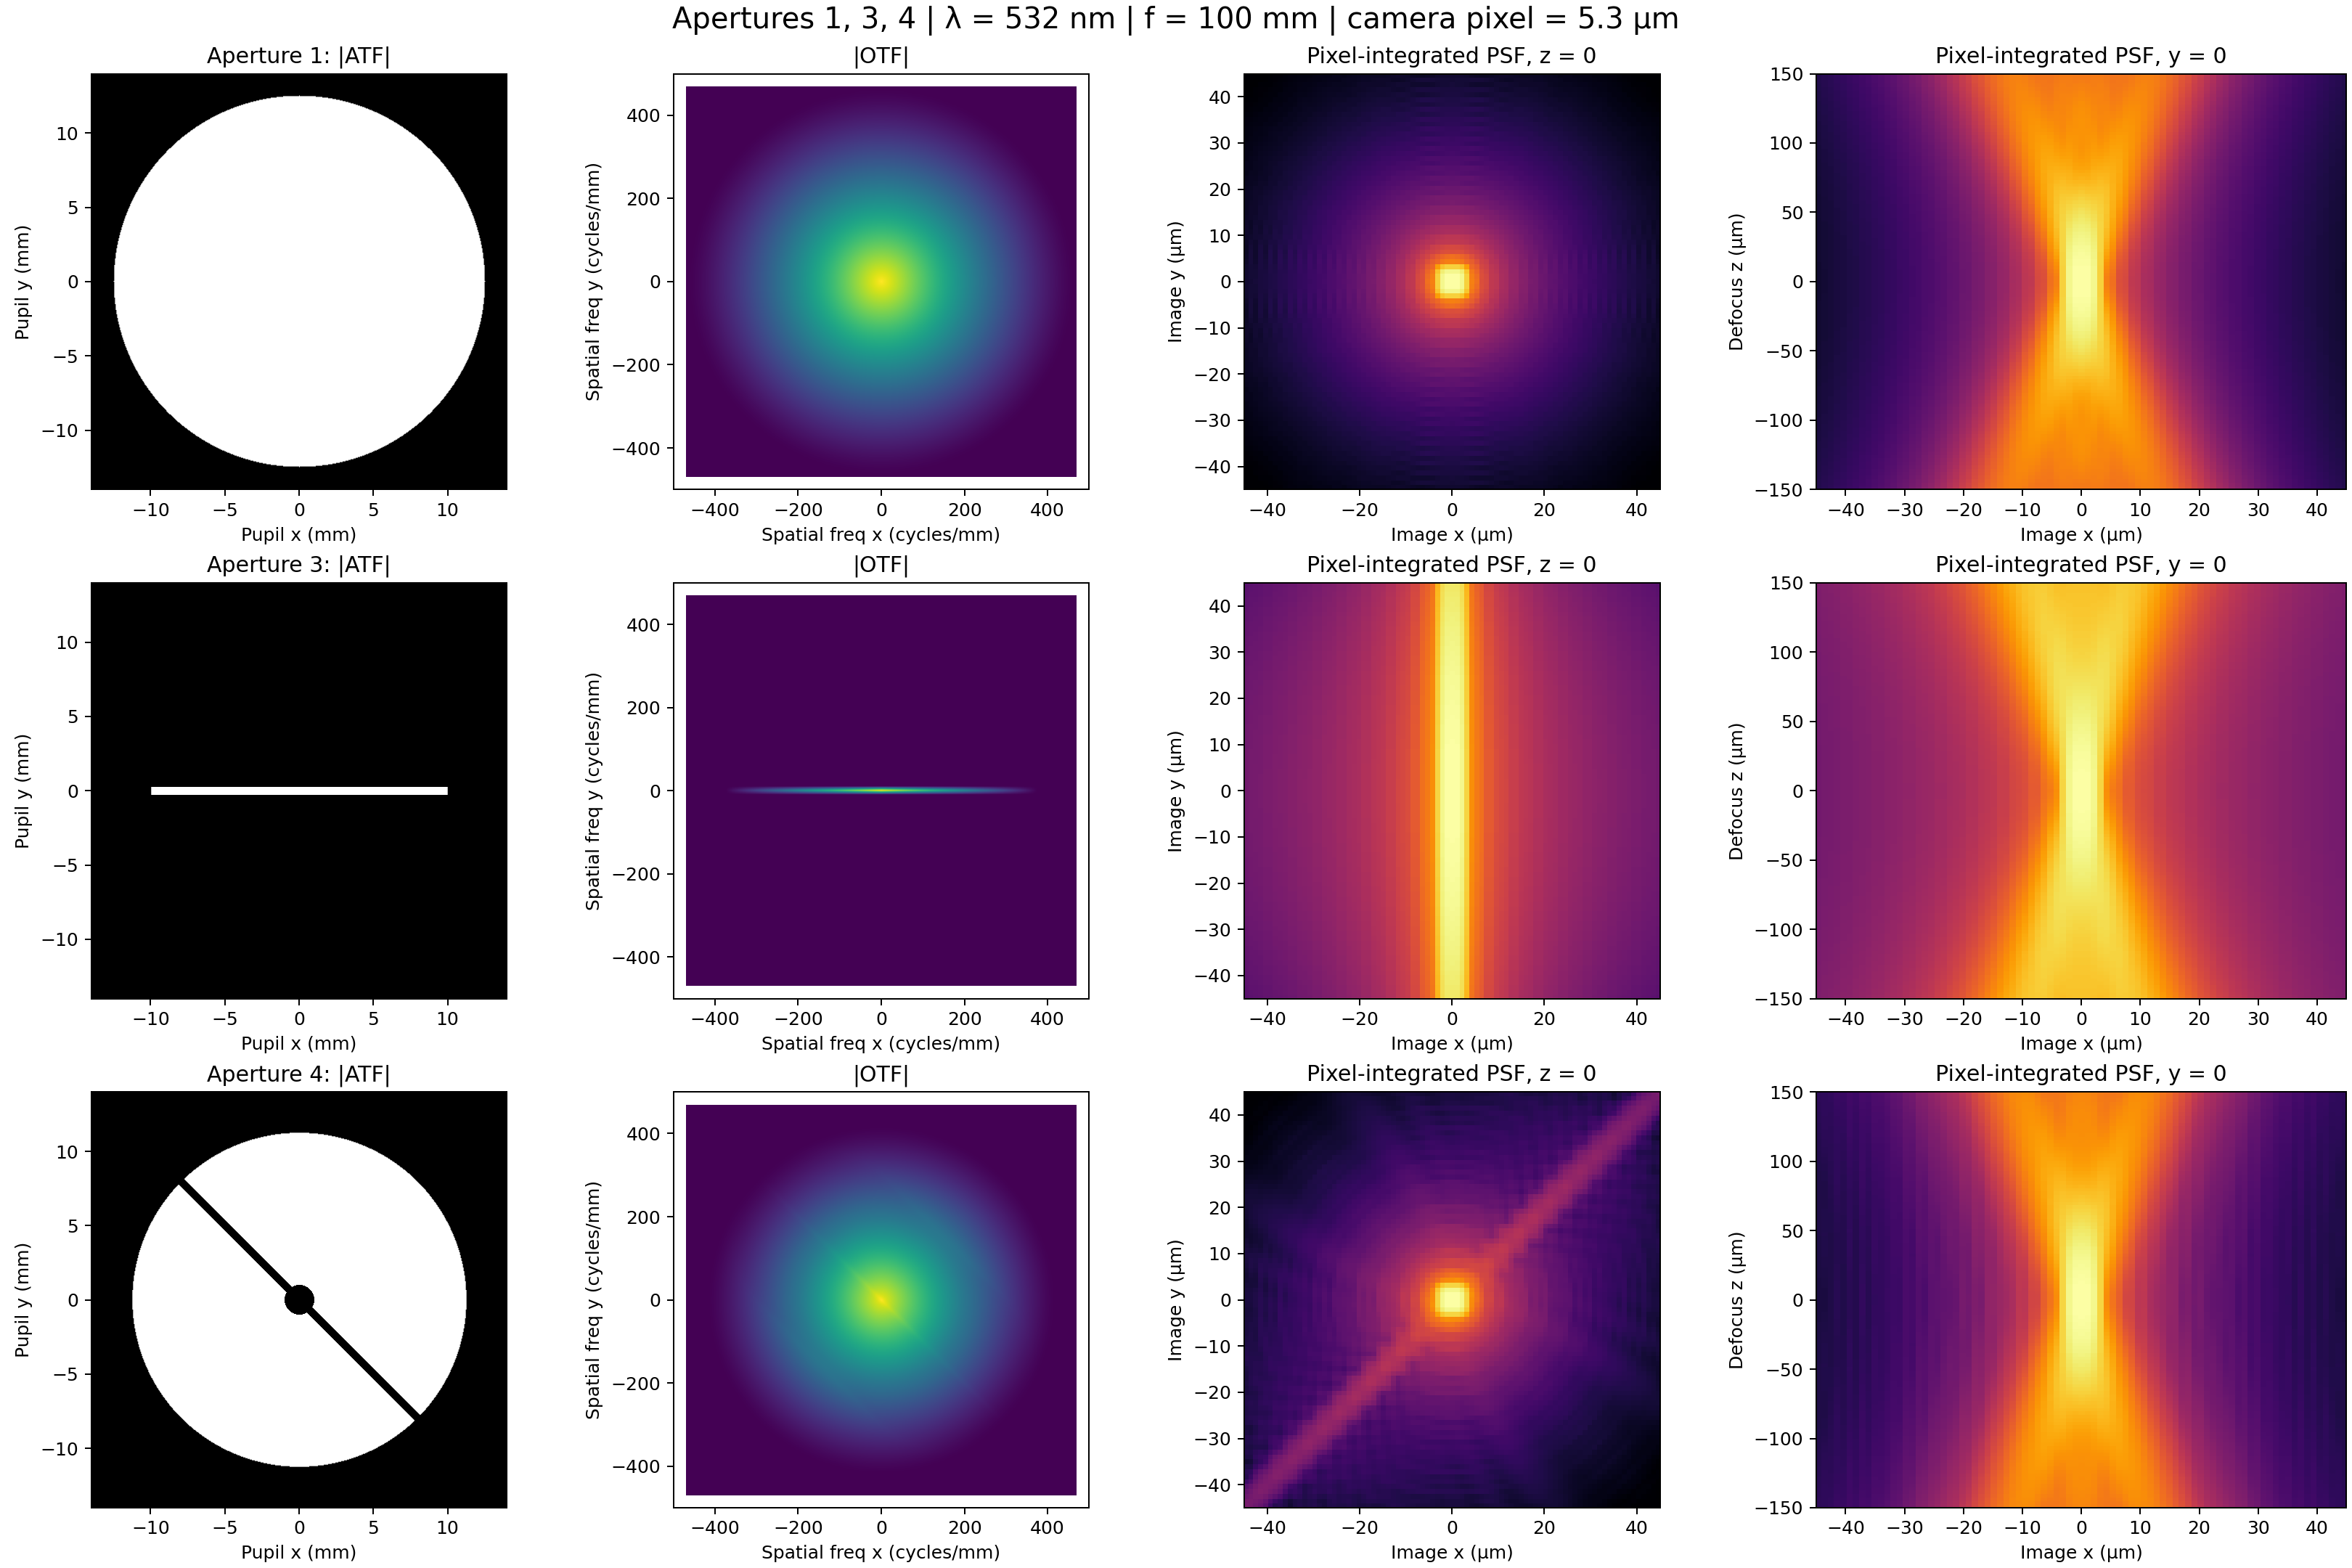

In [5]:
# Existing simulation output: ATF, in-focus OTF, xy PSF, and xz PSF.
display(Image(filename=str(root / 'ATF_PSF_OTF_comparison.png'), width=1050))

Figure 4. Simulated ATF, in-focus OTF, and pixel-integrated xy/xz PSFs for apertures 1, 3, and 4.

### 4. Simulation versus experiment

Three experimental stacks per aperture were aligned and averaged for comparison. Model coordinates were rescaled using the nominal 5× magnification.

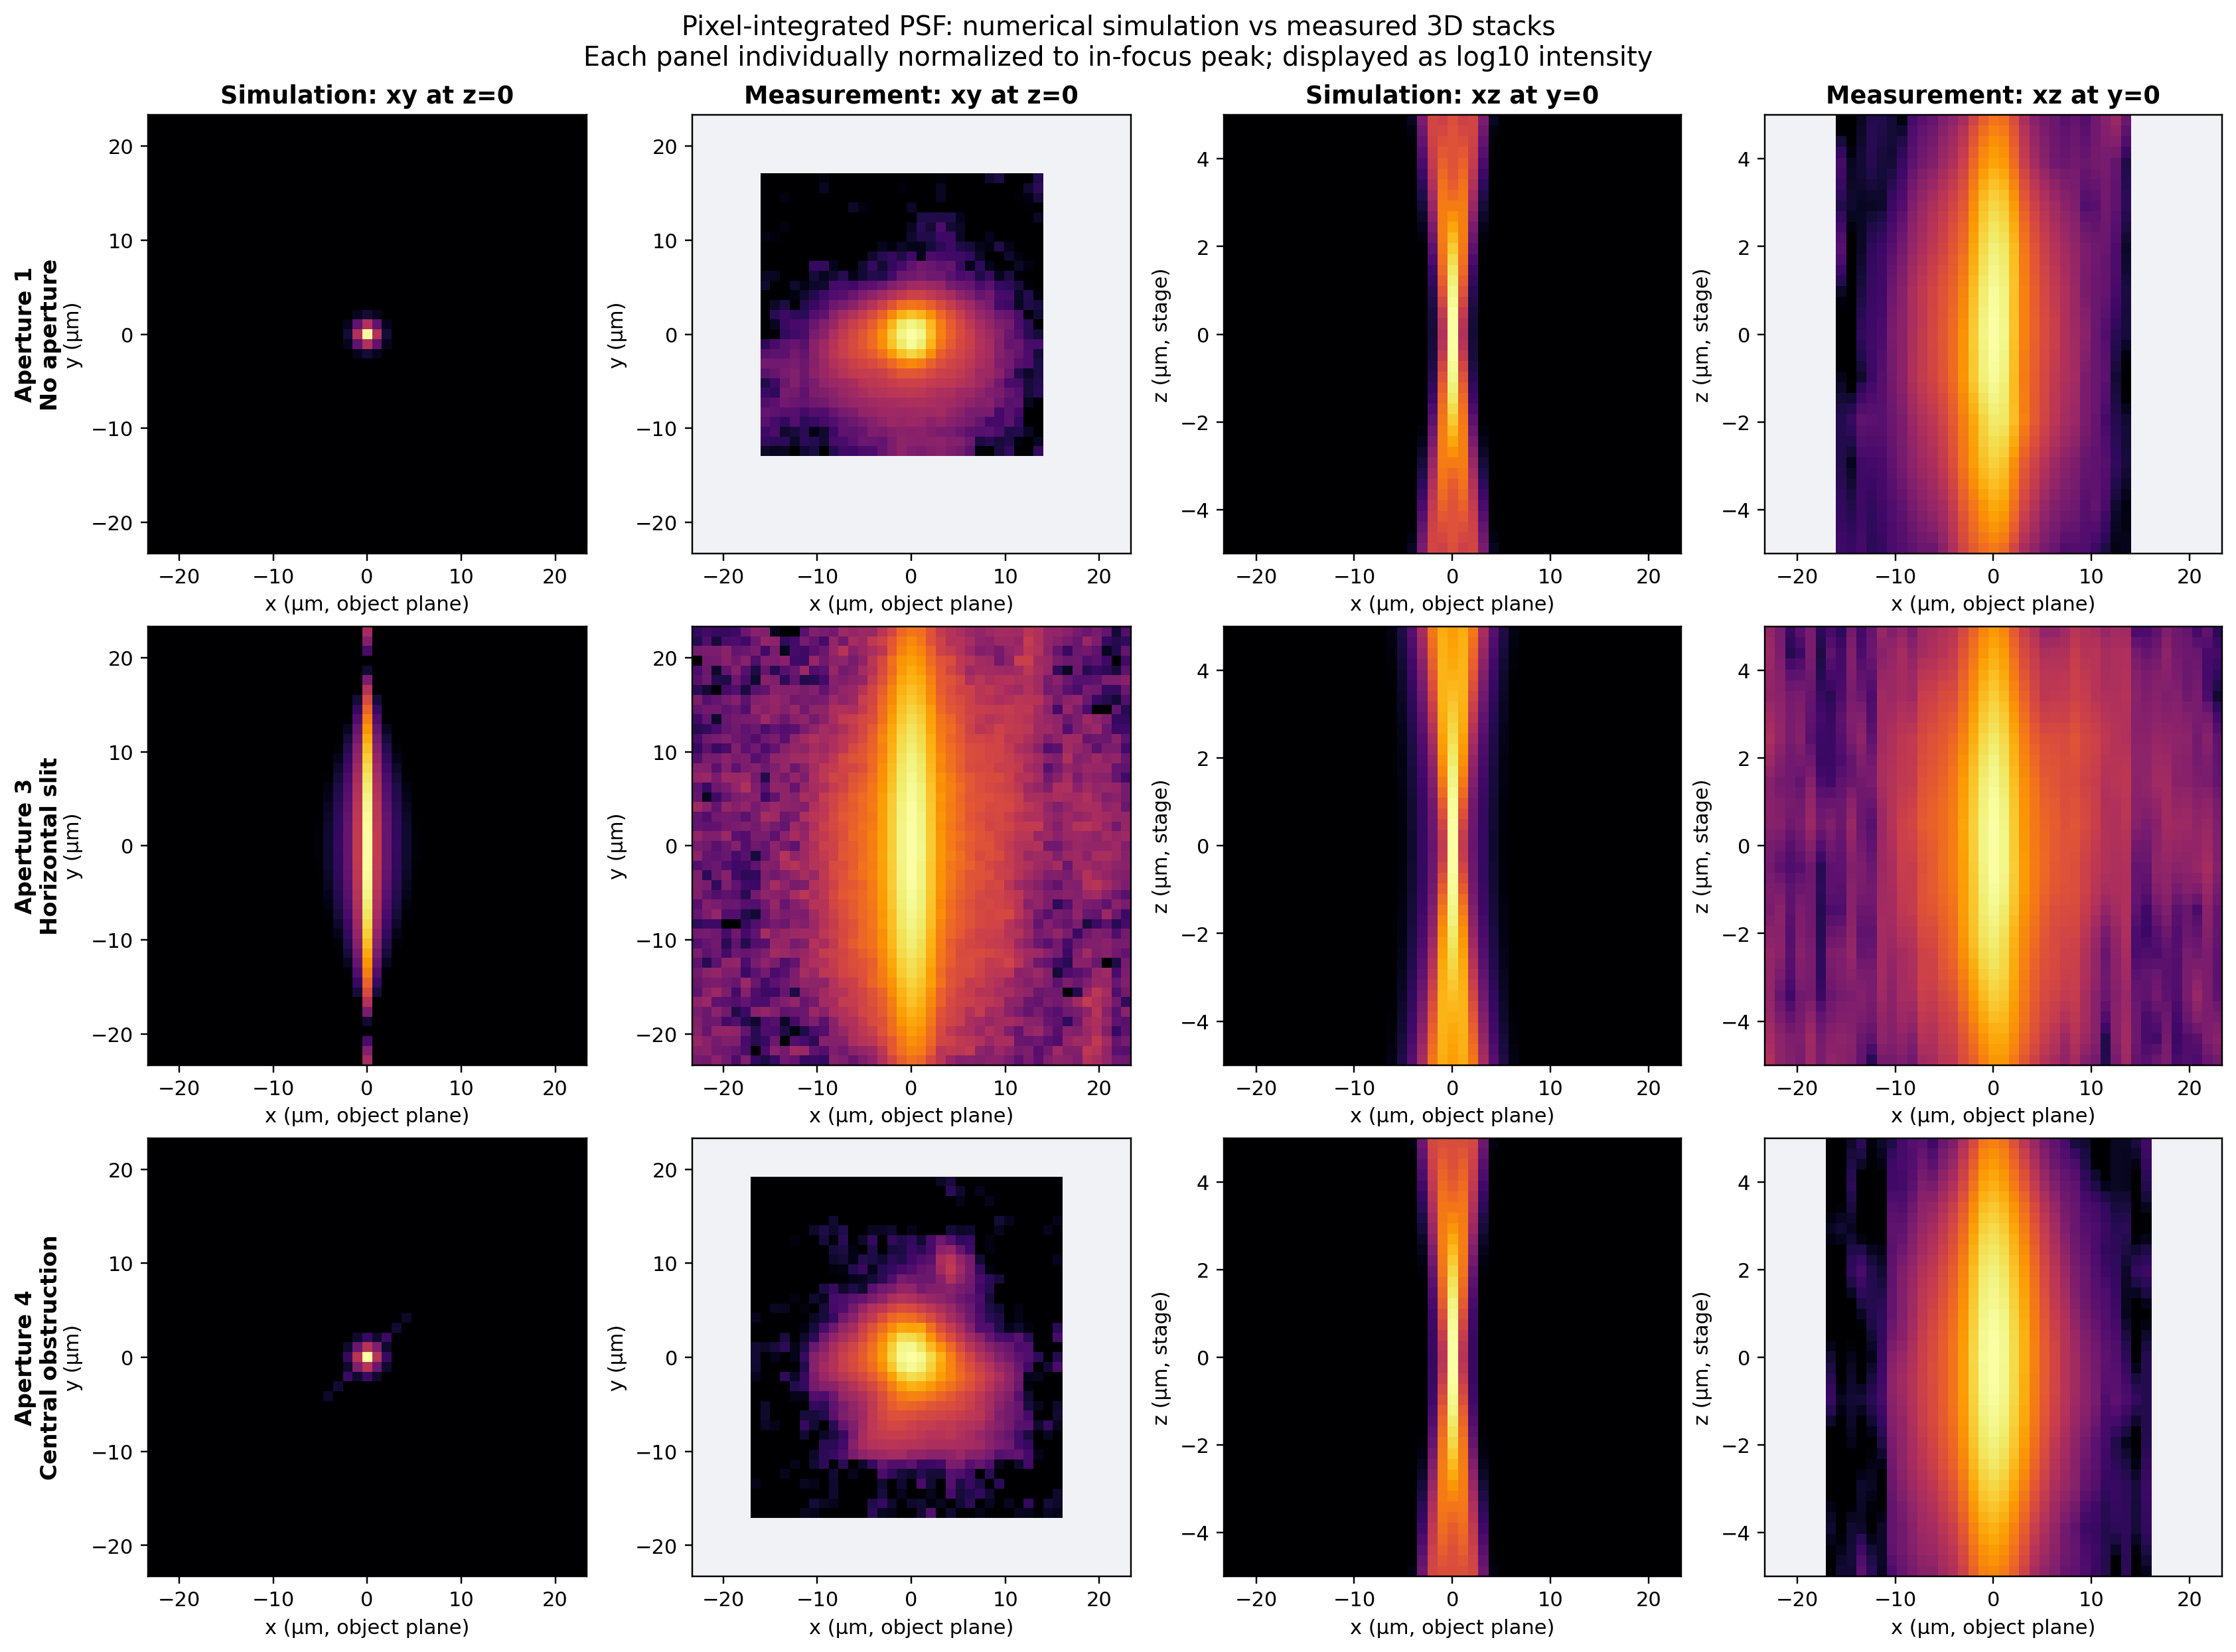

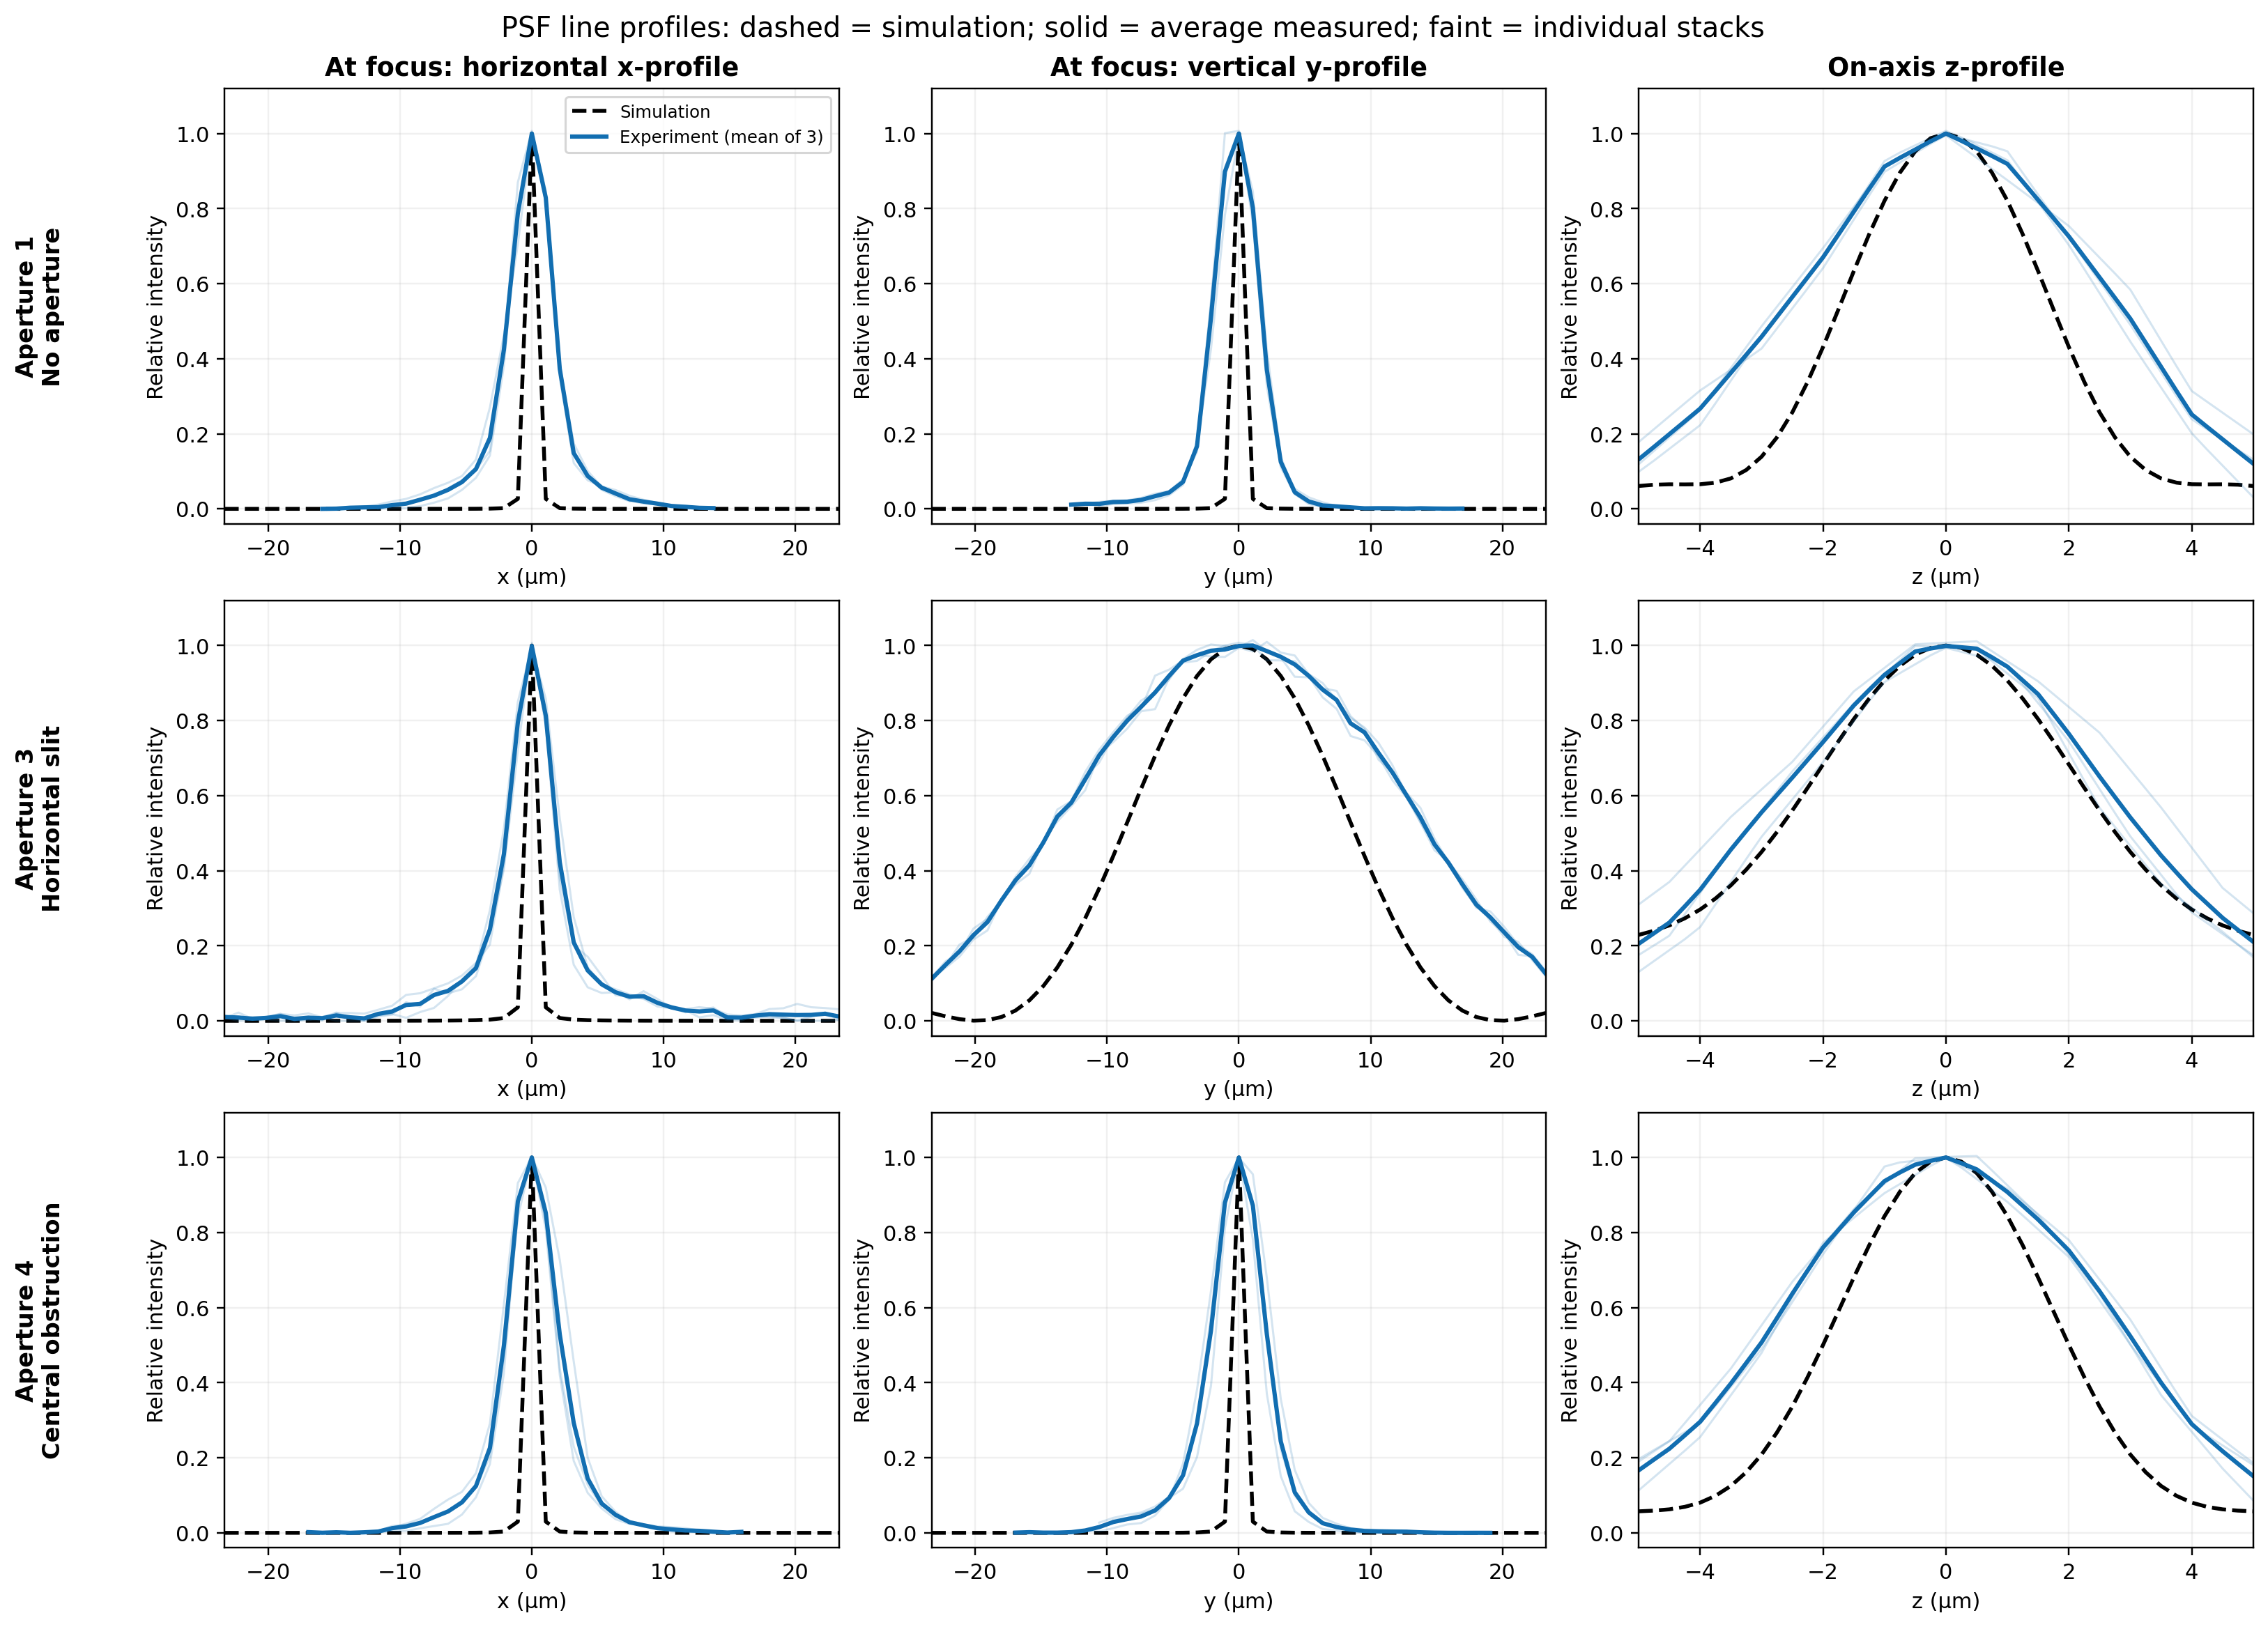

In [6]:
for filename in [
    'PSF_comparison/PSF_xy_xz_simulation_vs_experiment.png',
    'PSF_comparison/PSF_line_profiles.png']:
    display(Image(filename=str(root / filename), width=1050))

Figures 5–6. Comparison of simulated and measured xy/xz PSFs and x/y/z profiles. Intensities are normalized to compare shapes.

Approximate full widths at half maximum (FWHM, µm):

| Pupil | Simulation x / y / z | Measurement x / y / z |
|:--|--:|--:|
| 1 — open | 1.46 / 1.46 / 3.67 | 4.01 / 4.18 / 5.86 |
| 3 — slit | 1.48 / 17.67 / 5.55 | 4.22 / 28.91 / 6.50 |
| 4 — obstruction | 1.46 / 1.46 / 4.02 | 4.71 / 4.81 / 6.15 |

The open pupil gives an approximately symmetric lateral PSF. The slit broadens the PSF vertically, while the central obstruction changes its sidelobes. Measured PSFs are generally broader because of aberrations, alignment, bead size, and sampling. The widths are approximate owing to incomplete z-frame indexing and uncertain model scaling.